<a href="https://colab.research.google.com/github/rheevinenghog-creator/Enghog_ml_activity_02.ipynb/blob/main/Enghog.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [51]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

df = pd.read_csv('telecom_churn.csv')
print("Dataset loaded successfully. Shape:", df.shape)

print("\nMissing values before handling:", df.isnull().sum().sum())


X = df.drop(columns=['churn', 'phone number', 'state'])
y = df['churn']


Dataset loaded successfully. Shape: (3333, 21)

Missing values before handling: 0


In [52]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

In [54]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])


preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")


pipeline = Pipeline(steps=[('preprocessor', preprocessor)])
X_train_processed = pipeline.fit_transform(X_train)
X_test_processed = pipeline.transform(X_test)

print(f"Processed Training data shape: {X_train_processed.shape}")
print(f"Processed Testing data shape: {X_test_processed.shape}")

Training set shape: (2666, 18)
Testing set shape: (667, 18)
Processed Training data shape: (2666, 18)
Processed Testing data shape: (667, 18)


In [38]:

print("Target class proportions (Churn):")
print(f"Original: \n{y.value_counts(normalize=True)}")
print(f"Train:    \n{y_train.value_counts(normalize=True)}")
print(f"Test:     \n{y_test.value_counts(normalize=True)}")

Target class proportions (Churn):
Original: 
churn
False    0.855086
True     0.144914
Name: proportion, dtype: float64
Train:    
churn
False    0.855214
True     0.144786
Name: proportion, dtype: float64
Test:     
churn
False    0.854573
True     0.145427
Name: proportion, dtype: float64


In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("Models imported successfully.")

Models imported successfully.


In [40]:
model_a = LogisticRegression(max_iter=1000, random_state=42)

pipeline_a = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', model_a)
])

pipeline_a.fit(X_train, y_train)

print("Model A (Logistic Regression) trained successfully!")

Model A (Logistic Regression) trained successfully!


In [41]:
model_b = DecisionTreeClassifier(max_depth=5, random_state=42)

pipeline_b = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', model_b)
])

pipeline_b.fit(X_train, y_train)

print("Model B (Decision Tree) trained successfully!")

Model B (Decision Tree) trained successfully!


In [42]:
model_c = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)

pipeline_c = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', model_c)
])

pipeline_c.fit(X_train, y_train)

print("Model C (Random Forest) trained successfully!")

Model C (Random Forest) trained successfully!


In [43]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("Evaluation libraries imported.")

Evaluation libraries imported.


In [44]:
y_pred_a = pipeline_a.predict(X_test)
y_prob_a = pipeline_a.predict_proba(X_test)[:, 1]

y_pred_b = pipeline_b.predict(X_test)
y_prob_b = pipeline_b.predict_proba(X_test)[:, 1]

y_pred_c = pipeline_c.predict(X_test)
y_prob_c = pipeline_c.predict_proba(X_test)[:, 1]

print("Predictions and probabilities generated for all models.")

Predictions and probabilities generated for all models.


In [45]:
def get_metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred)
    }

metrics_a = get_metrics(y_test, y_pred_a)
metrics_b = get_metrics(y_test, y_pred_b)
metrics_c = get_metrics(y_test, y_pred_c)

summary_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Logistic Regression': [metrics_a['Accuracy'], metrics_a['Precision'], metrics_a['Recall'], metrics_a['F1-Score']],
    'Decision Tree': [metrics_b['Accuracy'], metrics_b['Precision'], metrics_b['Recall'], metrics_b['F1-Score']],
    'Random Forest': [metrics_c['Accuracy'], metrics_c['Precision'], metrics_c['Recall'], metrics_c['F1-Score']]
})

summary_df

,Metric,Logistic Regression,Decision Tree,Random Forest
0,Accuracy,0.859070,0.917541,0.905547
1,Precision,0.536585,0.756098,0.947368
2,Recall,0.226804,0.639175,0.371134
3,F1-Score,0.318841,0.692737,0.533333


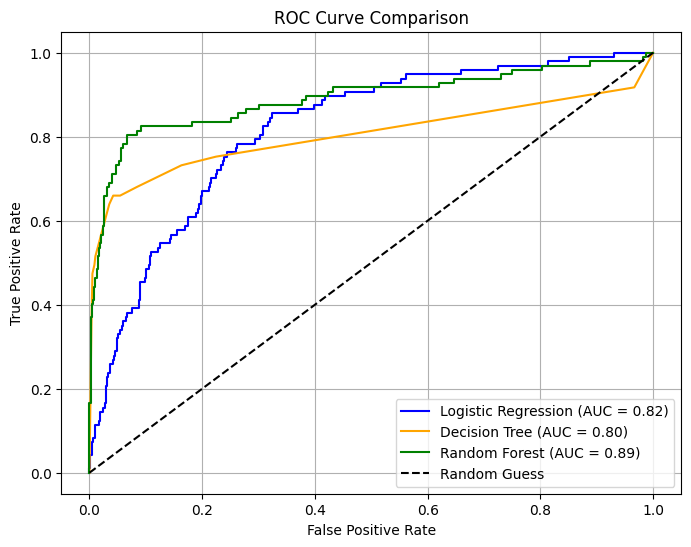

In [46]:
plt.figure(figsize=(8, 6))

fpr_a, tpr_a, _ = roc_curve(y_test, y_prob_a)
fpr_b, tpr_b, _ = roc_curve(y_test, y_prob_b)
fpr_c, tpr_c, _ = roc_curve(y_test, y_prob_c)

auc_a = auc(fpr_a, tpr_a)
auc_b = auc(fpr_b, tpr_b)
auc_c = auc(fpr_c, tpr_c)

plt.plot(fpr_a, tpr_a, label=f'Logistic Regression (AUC = {auc_a:.2f})', color='blue')
plt.plot(fpr_b, tpr_b, label=f'Decision Tree (AUC = {auc_b:.2f})', color='orange')
plt.plot(fpr_c, tpr_c, label=f'Random Forest (AUC = {auc_c:.2f})', color='green')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()